### Start Here: Obtain spectra for the sources and add additional spec-zs from SIMBAD

In [274]:
%matplotlib inline
import sys, os, glob, warnings

warnings.filterwarnings('ignore', category=UserWarning, module='astroquery')

from astropy.io import fits, ascii

from astroquery.simbad import Simbad
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
import astropy.constants as const
from astropy.coordinates import SkyCoord, concatenate, Angle
from astropy import table
from astropy.wcs import WCS
from astropy.table import Column, Table

In [275]:
# A token is needed to access ADS. Here I used mine. A token is available at https://ui.adsabs.harvard.edu/user/settings/token

from astroquery import nasa_ads as na

na.ADS.TOKEN = 'Gh2X1K7QxOgpUq0kU3eG3QWNuer5wV6CaIjgkGdp'
na.ADS.NROWS = 20
na.ADS.SORT = 'bibcode desc'
na.ADS.ADS_FIELDS = ['author','title','pubdate', 'bibcode'] # 'bibcode' must be in the field
def get_ref(bibcode): 
    results = na.ADS.query_simple('bibcode:'+bibcode)
    author = results['author'][0][0].split(',')[0]
    year = results['pubdate'][0][0:4]
    return author + year

# try it
#get_ref('2013ApJ...767..118C')

In [276]:
import scienceplots

plt.style.use(['bright', 'science', 'no-latex', 'notebook'])

### Read the variable AGN tables:

In [ ]:
# ID must be NSA ID
# Baldassare 2018,2020, Wasilewski 2022, Ward 2022

header = ['id', 'ra', 'dec', 'z', 'logMs', 'g', 'Rrms', 'sigmavar', 'sigmaqso', 'sigmanot', 'BPT', 'logMBH']
data_agn1 = ascii.read('bgg18.txt', fast_reader=False, guess=False, delimiter='\t', names=header)
data_agn1.remove_columns(['g', 'Rrms', 'sigmavar', 'sigmaqso', 'sigmanot', 'BPT', 'logMBH'])
data_agn1['logMs'] = np.log10(data_agn1['logMs'])

header = ['id', 'ra', 'dec', 'z', 'logMs', 'Npts', 'baseline', 'R', 'std', 'sigmavar', 'sigmaqso', 'sigmanot']
data_agn2 = ascii.read('bgg20.txt', fast_reader=False, guess=False, format='mrt', delimiter='\t', names=header)
data_agn2.remove_columns(['Npts', 'baseline', 'R', 'std', 'sigmavar', 'sigmaqso', 'sigmanot'])
data_agn2['id'] = np.array([i[3:] for i in data_agn2['id']], dtype=int)

header = ['id', 'ra', 'dec', 'logMs', 'z', 'NUV', 'sigma', 'Fvar', 'logMBH']
data_agn3 = ascii.read('wasleske22.txt', fast_reader=False, guess=False, delimiter='\t', names=header)
data_agn3.remove_columns(['NUV', 'sigma', 'Fvar', 'logMBH'])

header = ['id', 'ra', 'dec', 'z', 'logMs', 'logMBH', 'BPT', 'BLR', 'logMBHv']
data_agn4 = ascii.read('ward22.txt', fast_reader=False, guess=False, delimiter='\t', names=header)
# Convert coordinates
data_agn4['ra'] = [np.round(Angle(r, unit=u.hourangle).deg, 4) for r in data_agn4['ra']]
data_agn4['dec'] = [np.round(Angle(d, unit=u.deg).deg, 4) for d in data_agn4['dec']]
data_agn4.remove_columns(['logMBH', 'BPT', 'BLR', 'logMBHv'])

In [ ]:
# NON-Variability-selected (RV 15) sample
# https://arxiv.org/abs/1508.06274
#SDSS
data_rv = ascii.read('../rv15_t1.txt')
cs = [SkyCoord.from_name(n, parse=True) for n in data_rv['SDSS']]
data_rv['ra'] = concatenate(cs).ra.deg
data_rv['dec'] = concatenate(cs).dec.deg
data_rv['logMs'] = data_rv['logM*']
data_rv.remove_columns(['NSAID', 'SDSS', 'P-MJD-F', 'iMag', 'g-i', 'logM*'])
data_rv

ID,z,logMBH,ra,dec,logMs
,,dex(Msun),,,dex(Msun)
int64,float64,float64,float64,float64,float64
1,0.0422,6.21,2.2829166666666665,14.465499999999999,10.68
2,0.0424,7.07,10.653583333333332,-10.822777777777777,10.43
3,0.0548,7.65,20.499208333333332,-1.0400833333333335,10.47
4,0.0419,8.11,32.54787499999999,-9.059861111111111,10.92
5,0.0296,5.7,42.30358333333332,-8.257138888888889,10.11
6,0.0447,6.5,46.074041666666666,0.4742222222222222,10.61
7,0.0479,6.72,50.026333333333326,40.36627777777778,10.36
8,0.0388,6.76,62.37145833333333,-4.484083333333333,9.64


In [294]:
data_rv.write('rv_agn.txt', format='ascii', overwrite=True)

In [279]:
#data_agn = data_rv
data_agn = table.vstack([data_agn1, data_agn2, data_agn3, data_agn4])
data_agn['ID'] = range(len(data_agn))
data_agn.remove_columns(['id'])
data_agn['id'] = data_agn['ID']
data_agn['RA'] = data_agn['ra']
data_agn['DEC'] = data_agn['dec']

In [280]:
#data_agn = concatenate([data_agn1, data_agn2])
data_agn.write('local_agn.txt', format='ascii', overwrite=True)

In [281]:
cat_agn = SkyCoord(data_agn['ra'], data_agn['dec'], unit='deg')
data_agn

ra,dec,z,logMs,ID,id,RA,DEC
deg,deg,,dex(Msun),,,deg,deg
float64,float64,float64,float64,int64,int64,float64,float64
0.47615,0.125693,0.1395,9.885926339801431,0,0,0.47615,0.125693
2.36003,0.325606,0.1138,9.468347330412158,1,1,2.36003,0.325606
4.27033,-0.493348,0.0672,9.970811610872518,2,2,4.27033,-0.493348
6.96605,0.794382,0.0821,9.79657433321043,3,3,6.96605,0.794382
8.39416,0.048925,0.1067,9.90471554527868,4,4,8.39416,0.048925
8.15918,-1.009817,0.0917,9.961421094066448,5,5,8.15918,-1.009817
11.38946,-0.969121,0.1376,9.869231719730976,6,6,11.38946,-0.969121
11.51401,0.636591,0.1246,9.58092497567562,7,7,11.51401,0.636591


### Match to SIMBAD using `astroquery`

Description for `add_votable_fields` refers to:  
https://github.com/astropy/astroquery/blob/main/astroquery/simbad/data/votable_fields_dict.json

In [282]:
# mask_specz = np.isfinite(data_agn[r'z_sp'].data)

# print(len(data_agn[mask_specz]))

# Add the redshift information
customSimbad = Simbad()
customSimbad.add_votable_fields('otype', 'rvz_qual','rvz_wavelength','z_value', 'rvz_bibcode', 'flux(i)')

result_table = customSimbad.query_region(cat_agn, radius=1.0*u.arcsec)

print(np.unique(result_table['OTYPE']))

# Sources with RVZ_WAVELENGTH == 'O' or rvz_qual!='E' should have an optical spectrum
# Remove stars / CV

mask_spec_simbad = ((result_table['RVZ_WAVELENGTH']=='O') | (result_table['RVZ_WAVELENGTH']=='N'))  & (result_table['RVZ_QUAL']!='E') & (result_table['OTYPE']!='CataclyV*') & (result_table['OTYPE']!='Star') & (result_table['OTYPE']!='RRLyrae')

np.count_nonzero(mask_spec_simbad)

    OTYPE    
-------------
          AGN
AGN_Candidate
        BLLac
 BlueCompactG
    EmissionG
       Galaxy
   GtowardsCl
GtowardsGroup
         HIIG
       HIIReg
        PairG
      PartofG
          QSO
      Seyfert
     Seyfert1
     Seyfert2
   StarburstG
    Supernova
    Variable*


292

In [283]:
result_table[(result_table['OTYPE']=='Variable*')]

MAIN_ID,RA,DEC,RA_PREC,DEC_PREC,COO_ERR_MAJA,COO_ERR_MINA,COO_ERR_ANGLE,COO_QUAL,COO_WAVELENGTH,COO_BIBCODE,OTYPE,RVZ_QUAL,RVZ_WAVELENGTH,Z_VALUE,RVZ_BIBCODE,FLUX_i,SCRIPT_NUMBER_ID
,"""h:m:s""","""d:m:s""",,,mas,mas,deg,,,,,,,,,mag,
object,str13,str13,int16,int16,float32,float32,int16,str1,str1,object,object,str1,str1,float64,object,float32,int32
[EHV2002] 2-1-0076,14 07 53.0243,+53 36 51.410,14,14,0.248,0.288,90,A,O,2020yCat.1350....0G,Variable*,,,--,,--,310


In [284]:
result_table[(result_table['OTYPE']=='Supernova')]

MAIN_ID,RA,DEC,RA_PREC,DEC_PREC,COO_ERR_MAJA,COO_ERR_MINA,COO_ERR_ANGLE,COO_QUAL,COO_WAVELENGTH,COO_BIBCODE,OTYPE,RVZ_QUAL,RVZ_WAVELENGTH,Z_VALUE,RVZ_BIBCODE,FLUX_i,SCRIPT_NUMBER_ID
,"""h:m:s""","""d:m:s""",,,mas,mas,deg,,,,,,,,,mag,
object,str13,str13,int16,int16,float32,float32,int16,str1,str1,object,object,str1,str1,float64,object,float32,int32
SDSS-II SN 20259,22 24 35.293,-00 11 03.92,7,7,10.000,10.000,0,C,O,2012ApJS..203...21A,Supernova,C,O,0.0587300,2012ApJS..203...21A,--,34
iPTF 13cp,12 03 42.5568,+14 22 15.106,9,9,--,--,0,D,O,2021ApJS..255...29S,Supernova,D,O,0.0426000,2021ApJS..255...29S,--,95
SNF 20080515-004,15 44 04.33,+27 53 35.9,6,6,--,--,0,D,,,Supernova,,,--,,--,178
LSQ 14cnm,16 05 24.50,+01 12 58.7,6,6,--,--,0,D,,2014ATel.6254....1F,Supernova,D,,0.0326000,2014ATel.6254....1F,--,200


In [285]:
np.count_nonzero(mask_spec_simbad)

292

In [286]:
u, count = np.unique(result_table['RVZ_BIBCODE'], return_counts=True)
list(zip(u[np.argsort(-count)], count[np.argsort(-count)]))

[('2015ApJS..219...12A', 104),
 ('2012ApJS..203...21A', 98),
 ('2020ApJS..249....3A', 56),
 ('2009ApJS..182..543A', 30),
 ('', 9),
 ('2008A&A...485..657B', 6),
 ('2022ApJS..261...21Y', 5),
 ('2011yCat.2306....0A', 5),
 ('2002LEDA.........0P', 3),
 ('2022ApJS..261....2K', 2),
 ('2014ApJ...788...45T', 2),
 ('2023ApJS..267...17L', 2),
 ('2005RMxAA..41..155S', 1),
 ('1998AJ....115....6B', 1),
 ('1998AJ....116.1573B', 1),
 ('2021ApJS..255...29S', 1),
 ('1999ApJ...518...69M', 1),
 ('2020ApJ...902..145K', 1),
 ('2019MNRAS.485.2167G', 1),
 ('2018ApJS..237...11K', 1),
 ('2017ApJ...842...88S', 1),
 ('2017A&A...599A..81M', 1),
 ('2017A&A...597A..79P', 1),
 ('2016ApJS..226...11S', 1),
 ('2004AJ....128.1558S', 1),
 ('1999ApJS..122..415A', 1),
 ('2014ATel.6254....1F', 1),
 ('2014A&A...563A..54P', 1),
 ('2013ApJS..204...21M', 1),
 ('2000BSAO...49...32S', 1),
 ('2023ApJS..265...25J', 1),
 ('2001MNRAS.328.1039C', 1),
 ('2011MNRAS.414.3052D', 1),
 ('2009MNRAS.399..683J', 1),
 ('2003AJ....126.2081A', 1),

In [287]:
# SDSS, 6dF, LAMOST, DESI

In [288]:
result_table[(result_table['RVZ_QUAL']!='E')]

MAIN_ID,RA,DEC,RA_PREC,DEC_PREC,COO_ERR_MAJA,COO_ERR_MINA,COO_ERR_ANGLE,COO_QUAL,COO_WAVELENGTH,COO_BIBCODE,OTYPE,RVZ_QUAL,RVZ_WAVELENGTH,Z_VALUE,RVZ_BIBCODE,FLUX_i,SCRIPT_NUMBER_ID
,"""h:m:s""","""d:m:s""",,,mas,mas,deg,,,,,,,,,mag,
object,str13,str13,int16,int16,float32,float32,int16,str1,str1,object,object,str1,str1,float64,object,float32,int32
2SLAQ J000154.27+000732.4,00 01 54.2767,+00 07 32.440,14,14,0.360,0.321,90,A,O,2020yCat.1350....0G,Seyfert1,C,O,0.1395400,2015ApJS..219...12A,18.072,1
2SLAQ J000926.40+001932.2,00 09 26.4109,+00 19 32.252,14,14,0.359,0.371,90,A,O,2020yCat.1350....0G,Seyfert1,D,,0.1141800,2009ApJS..182..543A,18.832,2
2MASX J00170488-0029360,00 17 04.8700,-00 29 36.041,14,14,0.659,0.521,90,A,O,2020yCat.1350....0G,Galaxy,C,O,0.0671600,2012ApJS..203...21A,16.361,3
SDSS J002751.84+004739.6,00 27 51.8447,+00 47 39.818,14,14,15.930,9.174,90,C,O,2020yCat.1350....0G,Galaxy,C,O,0.0820700,2012ApJS..203...21A,16.901,4
SDSS J003334.58+000256.0,00 33 34.5860,+00 02 56.089,9,9,--,--,0,C,O,2009ApJS..182..543A,Galaxy,C,O,0.1067700,2009ApJS..182..543A,17.183,5
2MASS J00323821-0100352,00 32 38.2014,-01 00 35.327,14,14,0.159,0.114,90,A,O,2020yCat.1350....0G,Seyfert1,C,O,0.0917200,2012ApJS..203...21A,16.758,6
2SLAQ J004533.48-005808.8,00 45 33.4759,-00 58 08.838,14,14,0.228,0.146,90,A,O,2020yCat.1350....0G,Seyfert1,C,O,0.1376000,2012ApJS..203...21A,18.155,7
CAIRNS J004603.36+003811.8,00 46 03.3722,+00 38 12.024,14,14,51.956,20.649,90,C,O,2020yCat.1350....0G,Seyfert1,D,,0.1246500,2003AJ....126.2152R,17.497,8


display simbad bibcodes

DES: https://academic.oup.com/mnras/article/509/3/3547/6412546

OzDES? 2015MNRAS.452.3047Y

### Add new spec-z into the table

In [289]:
data_agn_updated = data_agn.copy()

data_agn_updated['z_simb'] = -1.
data_agn_updated['r_z_simb'] = ' '*19

idx = result_table['SCRIPT_NUMBER_ID'].data.data - 1
idx_simbad_specz = idx[mask_spec_simbad]


for j,i in enumerate(idx_simbad_specz):
    # Update if no existing spec-z
    # if ~np.isfinite(data_agn_updated[r'z_sp'][i]):
    data_agn_updated[r'z_simb'][i] = result_table[mask_spec_simbad]['Z_VALUE'][j]
    data_agn_updated[r'r_z_simb'][i] = result_table[mask_spec_simbad]['RVZ_BIBCODE'][j]

# mask_specz_updated = np.isfinite(data_agn_updated[r'z_sp'].data)
# print(len(data_agn_updated[mask_specz_updated]))
# mask_specz = np.isfinite(data_agn[r'z_sp'].data)
# print(len(data_agn[mask_specz]))


# Best spec-z
# Desi take priority over OzDES which takes priority over SIMBAD
data_agn_updated['z_best'] = data_agn['z']
data_agn_updated['z_best'][data_agn_updated['z_simb']>0] = data_agn_updated['z_simb'][data_agn_updated['z_simb']>0]

# Add ID
#data_agn_updated['ID'] = data_agn_updated['id']

print(len(data_agn_updated['z_best'][data_agn_updated['z_best']>0]))

print(len(data_agn_updated))

360
361


### Manually fix some:

In [290]:
#if 'comment' not in data_agn_updated.colnames:
#     data_agn_updated.add_column(table.Column(length=706, name='comment', dtype='U150'))

# ID: 47  0.61 arcsec away
#data_agn_updated['z_best'][47-1] = 1.256
#data_agn_updated['comment'][47-1] = '0.61 arcsec away, manually inputed redshift after changing SIMBAD radius parameter'

### Write data table

In [291]:
data_agn_updated.write('local_agn_updated.txt', format='ascii', overwrite=True)
data_agn_updated.write('localagn.fits', format='fits', overwrite=True)

## Gather photometry

We should do it two ways.

1. RainbowLasso (https://github.com/JohannesBuchner/RainbowLasso)
2. NASA-Sloan Atlas (https://www.sdss4.org/dr17/manga/manga-target-selection/nsa/)


### 1. RainbowLasso

cd ../../RainbowLasso

make localagn_all.fits

In [292]:
t = Table.read('localagn_all_lite.fits')
# rename columns to make cigale happy

t['redshift'] = t['z']

t.rename_column('FUV', 'galex.FUV')
t.rename_column('NUV', 'galex.NUV')
t.rename_column('decam_g', 'sdss.gp')
t.rename_column('decam_r', 'sdss.rp')
t.rename_column('decam_i', 'sdss.ip')
t.rename_column('decam_z', 'sdss.zp')
t.rename_column('UV_Y', 'vista.vircam.Y')
t.rename_column('UV_J', 'vista.vircam.J')
t.rename_column('UV_H', 'vista.vircam.H')
t.rename_column('UV_K', 'vista.vircam.Ks')
t.rename_column('WFCAM_Y', 'WFCAM_Y')
t.rename_column('WFCAM_J', 'WFCAM_J')
t.rename_column('WFCAM_H', 'WFCAM_H')
t.rename_column('WFCAM_Ks', 'WFCAM_K')

t.rename_column('FUV_err', 'galex.FUV_err')
t.rename_column('NUV_err', 'galex.NUV_err')
t.rename_column('decam_g_err', 'sdss.gp_err')
t.rename_column('decam_r_err', 'sdss.rp_err')
t.rename_column('decam_i_err', 'sdss.ip_err')
t.rename_column('decam_z_err', 'sdss.zp_err')
t.rename_column('UV_Y_err', 'vista.vircam.Y_err')
t.rename_column('UV_J_err', 'vista.vircam.J_err')
t.rename_column('UV_H_err', 'vista.vircam.H_err')
t.rename_column('UV_K_err', 'vista.vircam.Ks_err')
t.rename_column('WFCAM_Y_err', 'WFCAM_Y_err')
t.rename_column('WFCAM_J_err', 'WFCAM_J_err')
t.rename_column('WFCAM_H_err', 'WFCAM_H_err')
t.rename_column('WFCAM_Ks_err', 'WFCAM_K_err')

t.write('../cigale/local/data_phot.dat', format='ascii', overwrite=True, fill_values=[(ascii.masked, '-9999.0')])
t

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best,z_before,z_after,pointlike,inMzLSBASS,goodfitsLS,isolatedLS,W34_blended,galex.FUV,galex.NUV,galex.FUV_err,galex.NUV_err,sdss.gp,sdss.rp,sdss.ip,sdss.zp,sdss.gp_err,sdss.rp_err,sdss.ip_err,sdss.zp_err,90prime_r,90prime_g,zd_mosaic,90prime_r_err,zd_mosaic_err,90prime_g_err,vista.vircam.Y,vista.vircam.J,vista.vircam.H,vista.vircam.Ks,vista.vircam.Y_err,vista.vircam.J_err,vista.vircam.H_err,vista.vircam.Ks_err,WFCAM_Y,WFCAM_J,WFCAM_H,WFCAM_K,WFCAM_Y_err,WFCAM_J_err,WFCAM_H_err,WFCAM_K_err,WISE1_origin,WISE1,WISE1_err,WISE2_origin,WISE2,WISE2_err,WISE34_origin,WISE3,WISE3_err,WISE4,WISE4_err,redshift
deg,deg,,dex(Msun),,,deg,deg,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
float64,float64,float64,float64,int64,int64,float64,float64,float64,bytes19,float64,float64,float64,bool,bool,bool,bool,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bytes7,float64,float64,bytes7,float64,float64,bytes7,float64,float64,float64,float64,float64
0.47615,0.125693,0.1395,7690000000.0,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,0.1395,0.13954,False,False,False,True,False,-9.9e+27,0.020200524525697143,-9.9e+27,0.003901308300114176,0.0993800080469154,0.16793652931032832,0.2508588303431637,0.26427141760051304,0.0003422927294391881,0.00035285260987921187,0.0008437730749854024,0.0017487103234044357,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,0.3274383928380289,0.4141888466911869,0.5268614223635384,-99.0,0.0050774942158207685,0.008270380263168476,0.011296824632101393,0.2550054439433998,0.3137101656056705,0.3690460233885413,0.46346296532011266,0.00598681865899897,0.007359124644737259,0.014572617188652794,0.017102354310224298,LS10,0.37096283919157214,0.0021927123503009223,LS10,0.32291755954671914,0.003911321357335581,LS10,0.5668711580194675,0.058480754825599036,3.2316241433718105,0.27331063039447406,0.1395
2.36003,0.325606,0.1138,2940000000.0,1,1,2.36003,0.325606,-1.0,--,0.1138,0.1138,0.1138,True,False,True,False,True,-9.9e+27,0.06639390221822428,-9.9e+27,-0.06639390221822428,0.06958377398822267,0.0909990034883374,0.12573150872162211,0.12861199062837447,9.128542963899074e-05,0.00011233400485817162,0.00019758848264441627,0.0002371313196177655,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,0.14635770810022092,0.17256996062072966,0.17874734508828763,-99.0,0.004062574407196485,0.00488183569564933,0.0059051583489335285,0.11161670230002396,0.14862376594448617,0.15526717009145746,-99.0,0.004051939911331296,0.006120119605735774,0.009667338021753792,-99.0,LS10UL,0.22862211253667486,-0.22862211253667486,LS10UL,0.27652009332160965,-0.27652009332160965,AllWISE,0.8588476282120958,-0.8588476282120958,5700.0,-5700.0,0.1138
4.27033,-0.493348,0.0672,9350000000.0,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,0.0672,0.06716,False,False,True,True,False,-9.9e+27,0.06510329644668547,-9.9e+27,-0.06510329644668547,0.4731660379431854,0.8811518693689282,1.105042745049613,1.327821880297241,0.0002833550546606602,0.00046598205207860964,0.0008184126981808236,0.0012663848134143831,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.460917192452811,1.7832868209048396,1.6831437160268854,-99.0,0.007634371078156159,0.009262855572027981,0.0123539645336053,1.165965395344351,1.427626689169144,1.7562897309074,-99.0,0.010234355854884695,0.014040163787361433,0.01668647163650924,-99.0,LS10,0.8949884278377879,0.002836881728215233,LS10,0.6390439917740418,0.004455978778432764,LS10,1.4669635522164197,0.05829461583691962,1.6995161410204218,0.2711928428046316,0.0672
6.96605,0.794382,0.0821,6260000000.0,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207,0.0821,0.08207,False,False,True,True,False,-9.9e+27,0.062006133286140054,-9.9e+27,0.004738558001922147,0.3479504150751596,0.5413521680581335,-99.0,0.722437

In [244]:
t['vista.vircam.J'].data.data

array([0.32743839, 0.14635771, 1.46091719, 0.72079871, 0.32842877,
       1.00091961, 0.26180697, 0.42882333, 1.55958841, 0.26112761,
       0.25564682, 0.98550493, 0.30576403, 0.55692101, 0.62364178,
       0.56026565, 0.37231797, 0.30703932, 1.91003797, 0.8874445 ,
       0.57606621, 0.47410049, 0.55933501, 0.11996838, 0.1175468 ,
       0.32649941, 0.73582341, 0.26188559, 0.10192239, 0.12646292,
       0.44429395, 0.20529312, 0.16095245, 1.93511509,        nan,
              nan,        nan, 0.9704036 , 1.20300103,        nan,
       0.26802148, 0.12674616,        nan,        nan,        nan,
       0.09862304,        nan, 0.42137891, 1.2933093 , 0.41159984,
       0.42159437, 1.43855742, 0.83253711, 1.66187823,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        

In [219]:
data_agn_updated

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best
deg,deg,,dex(Msun),,,deg,deg,,,
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64
0.47615,0.125693,0.1395,7690000000.0,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954
2.36003,0.325606,0.1138,2940000000.0,1,1,2.36003,0.325606,-1.0,,0.1138
4.27033,-0.493348,0.0672,9350000000.0,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716
6.96605,0.794382,0.0821,6260000000.0,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207
8.39416,0.048925,0.1067,8030000000.0,4,4,8.39416,0.048925,0.10677,2009ApJS..182..543A,0.10677
8.15918,-1.009817,0.0917,9150000000.0,5,5,8.15918,-1.009817,0.09172,2012ApJS..203...21A,0.09172
11.38946,-0.969121,0.1376,7400000000.0,6,6,11.38946,-0.969121,0.1376,2012ApJS..203...21A,0.1376
11.51401,0.636591,0.1246,3810000000.0,7,7,11.51401,0.636591,-1.0,,0.1246


## Visualize SIMBAD update

visualize our update

In [220]:
data_agn_updated['z_before'] = data_agn_updated['z']
data_agn_updated['z_before'][data_agn_updated['z']>0] = data_agn_updated['z'][data_agn_updated['z']>0]

data_agn_updated['z_after'] = data_agn_updated['z_before']
data_agn_updated['z_after'][data_agn_updated['z_simb']>0] = data_agn_updated['z_simb'][data_agn_updated['z_simb']>0]

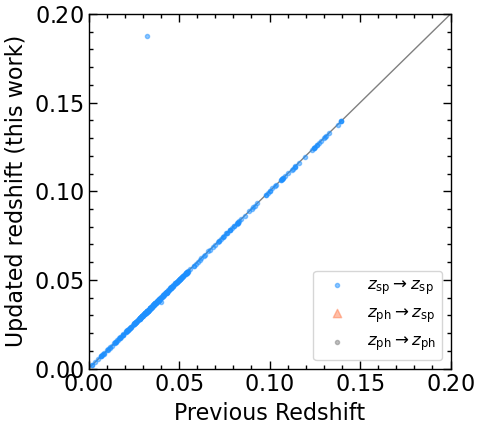

In [221]:
fig, ax = plt.subplots(1,1, figsize=(5, 4.5))

mask_sp_before = data_agn_updated['z']>0
mask_sp_after = (data_agn_updated['z']>0) | (data_agn_updated['z_simb']>0)

mask_sp2sp = mask_sp_before & mask_sp_after
ax.scatter(data_agn_updated['z_before'][mask_sp2sp], data_agn_updated['z_after'][mask_sp2sp], 
           marker='.', color='dodgerblue', label=r'$z_{\rm sp} \rightarrow z_{\rm sp}$', alpha=0.5)

mask_ph2sp = (~mask_sp_before) & mask_sp_after
ax.scatter(data_agn_updated['z_before'][mask_ph2sp], data_agn_updated['z_after'][mask_ph2sp], 
           marker='^', color='coral', label=r'$z_{\rm ph} \rightarrow z_{\rm sp}$', alpha=0.5)

mask_ph2ph = (~mask_sp_before) & (~mask_sp_after)
ax.scatter(data_agn_updated['z_before'][mask_ph2ph], data_agn_updated['z_after'][mask_ph2ph], 
           marker='.', color='gray', label=r'$z_{\rm ph} \rightarrow z_{\rm ph}$', alpha=0.5)

ax.plot([0, 4.5], [0, 4.5], lw=1, zorder=-2, color='gray')
ax.set_xlabel('Previous Redshift')
ax.set_ylabel('Updated redshift (this work)')
ax.legend(frameon=True, loc='lower right', fontsize=12)
ax.set_xlim(0, 0.2)
ax.set_ylim(0, 0.2)
fig.savefig('specz.pdf', dpi=300)

fig.tight_layout()

check inconsistency

In [224]:
data_agn_updated

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best,z_before,z_after
deg,deg,,dex(Msun),,,deg,deg,,,,,
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64,float64,float64
0.47615,0.125693,0.1395,7690000000.0,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,0.1395,0.13954
2.36003,0.325606,0.1138,2940000000.0,1,1,2.36003,0.325606,-1.0,,0.1138,0.1138,0.1138
4.27033,-0.493348,0.0672,9350000000.0,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,0.0672,0.06716
6.96605,0.794382,0.0821,6260000000.0,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207,0.0821,0.08207
8.39416,0.048925,0.1067,8030000000.0,4,4,8.39416,0.048925,0.10677,2009ApJS..182..543A,0.10677,0.1067,0.10677
8.15918,-1.009817,0.0917,9150000000.0,5,5,8.15918,-1.009817,0.09172,2012ApJS..203...21A,0.09172,0.0917,0.09172
11.38946,-0.969121,0.1376,7400000000.0,6,6,11.38946,-0.969121,0.1376,2012ApJS..203...21A,0.1376,0.1376,0.1376
11.51401,0.636591,0.1246,3810000000.0,7,7,11.51401,0.636591,-1.0,,0.1246,0.1246,0.1246
